# Store Sales Forecasting for a Retail Chain (Rossmann)
NextGen Institute · Machine Learning · Final Project

**Problem.** A chain of 1,115 stores must plan staff and stock six weeks ahead. This project forecasts daily sales per store from promotions, holidays, competition, store type and calendar features.

**Decision supported:** staffing levels, stock orders and promotion timing.
**Target:** `Sales` (daily, per open store), modeled as log(1 + Sales).
**Business metric:** RMSPE (the official competition metric). It measures error relative to actual sales, so small and large stores count equally. MAE, RMSE and R² are reported too.
**Dataset:** [Rossmann Store Sales (Kaggle)](https://www.kaggle.com/c/rossmann-store-sales), ~1M daily records, 1,115 stores, 2013-01-01 to 2015-07-31.

**Contents:** 1. Data understanding · 2. Cleaning & time-based split · 3. EDA · 4. Feature engineering & pipeline · 5. Modeling · 6. Tuning & validation · 7. Final evaluation · 8. Business insight · 9. Deployment
> **To run:** download `train.csv` and `store.csv` from the [Kaggle competition page](https://www.kaggle.com/c/rossmann-store-sales) (accept the rules first) and set `DATA_PATH` below to the folder that contains them.
---



## 1. Data understanding
We load the daily sales table (`train.csv`) and the store metadata (`store.csv`), then merge them on `Store`. Note that the Kaggle `test.csv` has no `Sales` column, so we build our own time-based test set later.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount("/content/drive")

DATA_PATH = "/content/drive/MyDrive/NextGen_Final_Project/rossman/"

Mounted at /content/drive


In [2]:
train = pd.read_csv(DATA_PATH + "train.csv", parse_dates=["Date"], low_memory=False)
store = pd.read_csv(DATA_PATH + "store.csv")

print("train:", train.shape)
print("store:", store.shape)
train.head()

train: (1017209, 9)
store: (1115, 10)


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday
0,1,5,2015-07-31,5263,555,1,1,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1


In [3]:
df = train.merge(store, on="Store", how="left")
print("merged:", df.shape)
print("Date range:", df["Date"].min(), "→", df["Date"].max())
df.head()

merged: (1017209, 18)
Date range: 2013-01-01 00:00:00 → 2015-07-31 00:00:00


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,Assortment,CompetitionDistance,CompetitionOpenSinceMonth,CompetitionOpenSinceYear,Promo2,Promo2SinceWeek,Promo2SinceYear,PromoInterval
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.0,9.0,2008.0,0,NaN,NaN,NaN
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.0,11.0,2007.0,1,13.0,2010.0,"Jan,Apr,Jul,Oct"
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.0,12.0,2006.0,1,14.0,2011.0,"Jan,Apr,Jul,Oct"
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.0,9.0,2009.0,0,NaN,NaN,NaN
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.0,4.0,2015.0,0,NaN,NaN,NaN


In [4]:
df.info()
print("\nMissing values (%):")
print((df.isnull().mean() * 100).round(2).sort_values(ascending=False).head(10))
print("\nDuplicates:", df.duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1017209 entries, 0 to 1017208
Data columns (total 18 columns):
 #   Column                     Non-Null Count    Dtype         
---  ------                     --------------    -----         
 0   Store                      1017209 non-null  int64         
 1   DayOfWeek                  1017209 non-null  int64         
 2   Date                       1017209 non-null  datetime64[ns]
 3   Sales                      1017209 non-null  int64         
 4   Customers                  1017209 non-null  int64         
 5   Open                       1017209 non-null  int64         
 6   Promo                      1017209 non-null  int64         
 7   StateHoliday               1017209 non-null  object        
 8   SchoolHoliday              1017209 non-null  int64         
 9   StoreType                  1017209 non-null  object        
 10  Assortment                 1017209 non-null  object        
 11  CompetitionDistance        1014567 no

,count,mean,min,25%,50%,75%,max,std
Store,1017209.0,558.429727,1.0,280.0,558.0,838.0,1115.0,321.908651
DayOfWeek,1017209.0,3.998341,1.0,2.0,4.0,6.0,7.0,1.997391
Date,1017209,2014-04-11 01:30:42.846061824,2013-01-01 00:00:00,2013-08-17 00:00:00,2014-04-02 00:00:00,2014-12-12 00:00:00,2015-07-31 00:00:00,NaN
Sales,1017209.0,5773.818972,0.0,3727.0,5744.0,7856.0,41551.0,3849.926175
Customers,1017209.0,633.145946,0.0,405.0,609.0,837.0,7388.0,464.411734
Open,1017209.0,0.830107,0.0,1.0,1.0,1.0,1.0,0.375539
Promo,1017209.0,0.381515,0.0,0.0,0.0,1.0,1.0,0.485759
SchoolHoliday,1017209.0,0.178647,0.0,0.0,0.0,0.0,1.0,0.383056
CompetitionDistance,1014567.0,5430.085652,20.0,710.0,2330.0,6890.0,75860.0,7715.3237
CompetitionOpenSinceMonth,693861.0,7.222866,1.0,4.0,8.0,10.0,12.0,3.211832


**Findings**
- 1,017,209 rows, 18 columns, no duplicates.
- `Promo2SinceWeek`, `Promo2SinceYear` and `PromoInterval` are missing for ~50% of rows: these are stores with `Promo2 = 0`, so the value means "not applicable", not an error.
- `CompetitionOpenSince*` is missing for ~32% (unknown opening date); `CompetitionDistance` for 0.26%.
- `Customers` is highly informative but is **not known at forecast time**, so it is excluded to avoid leakage.

### Data quality checks
Closed days, zero-sales days, unusual competition years and store coverage.

In [5]:
print(df["StateHoliday"].value_counts(dropna=False))
print("\nOpen value counts:\n", df["Open"].value_counts())

print("\nSales on closed days (should be 0):")
print(df[df["Open"] == 0]["Sales"].describe())

print("\nOpen but Sales = 0:", ((df["Open"] == 1) & (df["Sales"] == 0)).sum())

StateHoliday
0    986159
a     20260
b      6690
c      4100
Name: count, dtype: int64

Open value counts:
 Open
1    844392
0    172817
Name: count, dtype: int64

Sales on closed days (should be 0):
count    172817.0
mean          0.0
std           0.0
min           0.0
25%           0.0
50%           0.0
75%           0.0
max           0.0
Name: Sales, dtype: float64

Open but Sales = 0: 54


In [6]:
days_per_store = df.groupby("Store")["Date"].nunique()
print("Days per store → min/median/max:", days_per_store.min(), days_per_store.median(), days_per_store.max())
print("Stores with < 942 days:", (days_per_store < 942).sum())

print("\nSuspicious competition years (< 2000):")
print(df[df["CompetitionOpenSinceYear"] < 2000][["Store", "CompetitionOpenSinceYear"]].drop_duplicates())

Days per store → min/median/max: 758 942.0 942
Stores with < 942 days: 181

Suspicious competition years (< 2000):
      Store  CompetitionOpenSinceYear
20       21                    1999.0
112     113                    1999.0
145     146                    1961.0
209     210                    1999.0
222     223                    1995.0
328     329                    1990.0
449     450                    1994.0
540     541                    1990.0
570     571                    1995.0
606     607                    1999.0
706     707                    1990.0
732     733                    1999.0
764     765                    1999.0
814     815                    1900.0
832     833                    1999.0
949     950                    1994.0
968     969                    1999.0
991     992                    1990.0
1038   1039                    1990.0
1050   1051                    1998.0


In [7]:
all_dates = pd.date_range(df["Date"].min(), df["Date"].max())
short_stores = days_per_store[days_per_store < 942].index

missing_dates = []
for s in short_stores[:200]:
    present = set(df.loc[df["Store"] == s, "Date"])
    gaps = [d for d in all_dates if d not in present]
    missing_dates.append((s, gaps[0], gaps[-1], len(gaps)))

gap_df = pd.DataFrame(missing_dates, columns=["Store", "gap_start", "gap_end", "gap_days"])
print(gap_df["gap_start"].value_counts().head())
print(gap_df["gap_end"].value_counts().head())
gap_df.head()

gap_start
2014-07-01    180
2013-01-01      1
Name: count, dtype: int64
gap_end
2014-12-31    180
2013-01-01      1
Name: count, dtype: int64


,Store,gap_start,gap_end,gap_days
0,13,2014-07-01,2014-12-31,184
1,20,2014-07-01,2014-12-31,184
2,22,2014-07-01,2014-12-31,184
3,32,2014-07-01,2014-12-31,184
4,36,2014-07-01,2014-12-31,184


**Findings**
- 17% of rows are closed days and all have `Sales = 0`; 54 open days also have zero sales.
- 180 stores have no records between 2014-07-01 and 2014-12-31 (same window for all of them). We do not impute this gap.
- Competition years of 1900 and 1961 are not plausible and will be set to missing.

## 2. Cleaning & time-based split
### Cleaning
- Remove closed days (172,817 rows) and open days with zero sales (54 rows): their sales are 0, which would also break RMSPE (division by actual sales).
- Set implausible competition opening years (< 1990) to missing.
- Add calendar features: year, month, day, week of year.

In [8]:
df_clean = df[(df["Open"] == 1) & (df["Sales"] > 0)].copy()

df_clean.loc[df_clean["CompetitionOpenSinceYear"] < 1990, "CompetitionOpenSinceYear"] = np.nan

df_clean["Year"] = df_clean["Date"].dt.year
df_clean["Month"] = df_clean["Date"].dt.month
df_clean["Day"] = df_clean["Date"].dt.day
df_clean["WeekOfYear"] = df_clean["Date"].dt.isocalendar().week.astype(int)

print("Before:", df.shape, "→ After:", df_clean.shape)
print("Removed:", len(df) - len(df_clean), "rows")

Before: (1017209, 18) → After: (844338, 22)
Removed: 172871 rows


### Time-based split (no random split)
Random splitting would let the model see the future. We split by date, with each block matching the 6-week forecast horizon:
- **Train:** 2013-01-01 → 2015-05-08
- **Validation:** 2015-05-09 → 2015-06-19 (model selection)
- **Test:** 2015-06-20 → 2015-07-31 (touched once, at the end)

In [9]:
test_start = df_clean["Date"].max() - pd.Timedelta(days=41)
val_start  = test_start - pd.Timedelta(days=42)

train_df = df_clean[df_clean["Date"] < val_start]
val_df   = df_clean[(df_clean["Date"] >= val_start) & (df_clean["Date"] < test_start)]
test_df  = df_clean[df_clean["Date"] >= test_start]

for name, d in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s} {d['Date'].min().date()} → {d['Date'].max().date()}  rows={len(d):,}")

train 2013-01-01 → 2015-05-08  rows=766,584
val   2015-05-09 → 2015-06-19  rows=37,472
test  2015-06-20 → 2015-07-31  rows=40,282


## 3. Exploratory data analysis
All EDA uses the training period only, so no decision is based on validation or test data.
### Target distribution

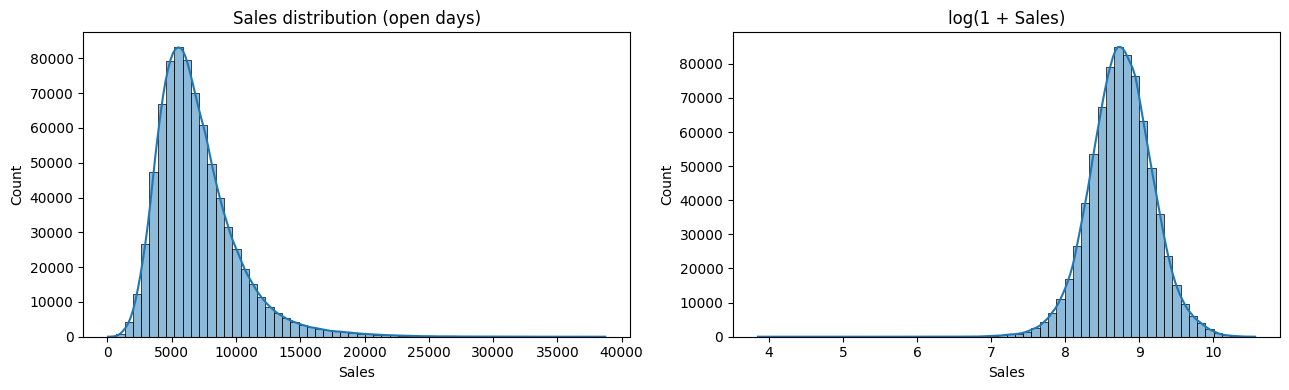

Skewness: 1.6


In [10]:
open_df = train_df

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(open_df["Sales"], bins=60, kde=True, ax=ax[0])
ax[0].set_title("Sales distribution (open days)")
sns.histplot(np.log1p(open_df["Sales"]), bins=60, kde=True, ax=ax[1])
ax[1].set_title("log(1 + Sales)")
plt.tight_layout()
plt.show()

print("Skewness:", open_df["Sales"].skew().round(2))

Sales are right-skewed (skewness 1.6); log(1 + Sales) is close to normal. We therefore train on the log scale and convert predictions back with `expm1`.

### Sales over time

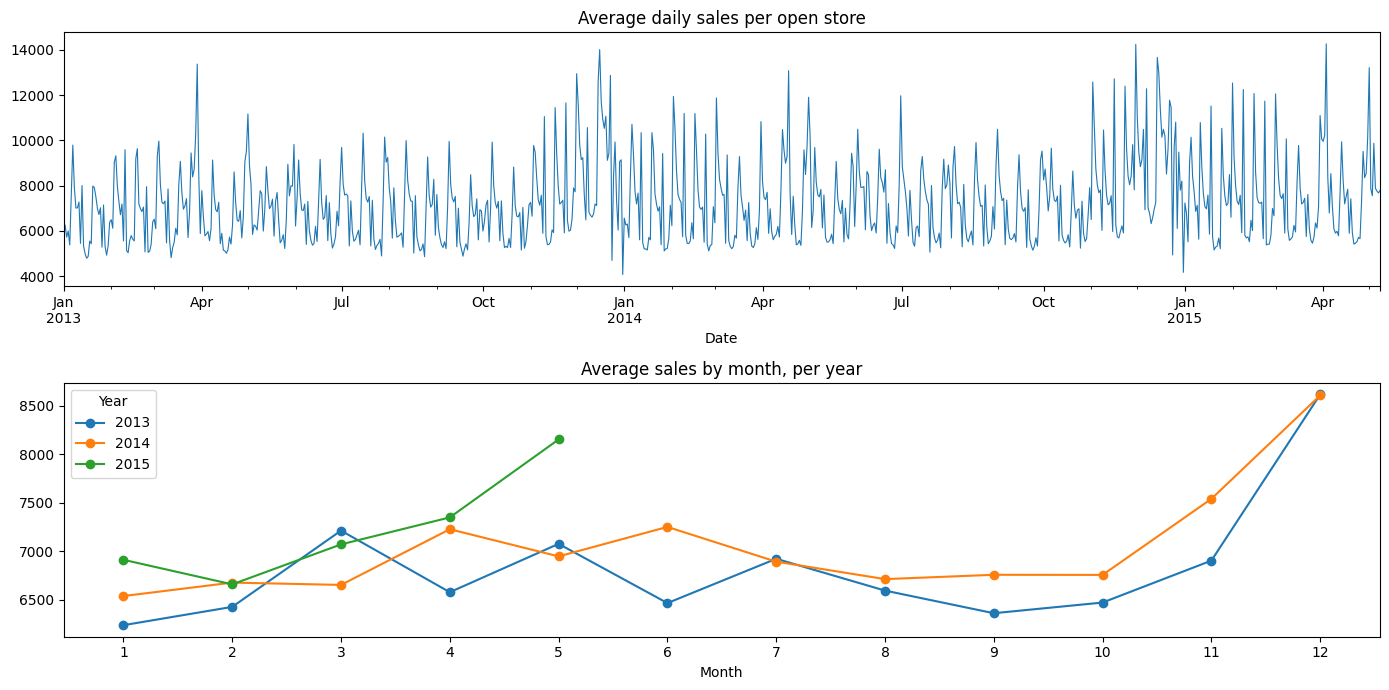

In [11]:
daily = train_df.groupby("Date")["Sales"].mean()

fig, ax = plt.subplots(2, 1, figsize=(14, 7))
daily.plot(ax=ax[0], lw=0.8)
ax[0].set_title("Average daily sales per open store")

monthly = train_df.groupby(["Year", "Month"])["Sales"].mean().unstack(0)
monthly.plot(ax=ax[1], marker="o")
ax[1].set_title("Average sales by month, per year")
ax[1].set_xticks(range(1, 13))
plt.tight_layout(); plt.show()

### Promotions, day of week and holidays

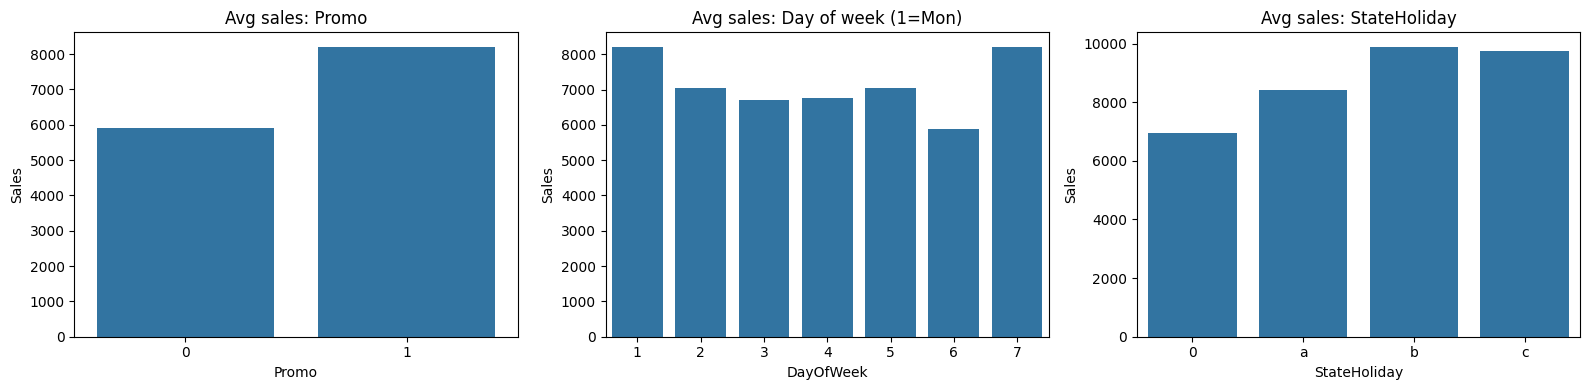

Promo
0    5907.0
1    8205.0
Name: Sales, dtype: float64
SchoolHoliday
0    6887.0
1    7159.0
Name: Sales, dtype: float64


In [12]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.barplot(data=train_df, x="Promo", y="Sales", ax=ax[0], errorbar=None)
ax[0].set_title("Avg sales: Promo")

sns.barplot(data=train_df, x="DayOfWeek", y="Sales", ax=ax[1], errorbar=None)
ax[1].set_title("Avg sales: Day of week (1=Mon)")

sns.barplot(data=train_df, x="StateHoliday", y="Sales", ax=ax[2], errorbar=None)
ax[2].set_title("Avg sales: StateHoliday")
plt.tight_layout(); plt.show()

print(train_df.groupby("Promo")["Sales"].mean().round(0))
print(train_df.groupby("SchoolHoliday")["Sales"].mean().round(0))

### Store type, assortment and competition

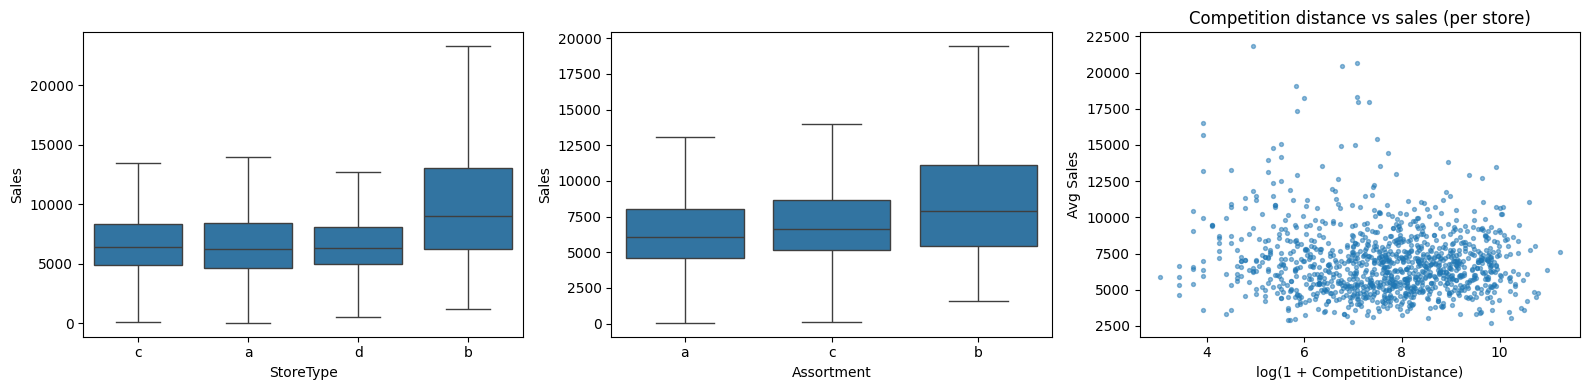

              mean   count
StoreType                 
a           6917.0  415148
b          10157.0   14132
c           6926.0  102679
d           6790.0  234625


In [13]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

sns.boxplot(data=train_df, x="StoreType", y="Sales", ax=ax[0], showfliers=False)
sns.boxplot(data=train_df, x="Assortment", y="Sales", ax=ax[1], showfliers=False)

store_avg = train_df.groupby("Store").agg(Sales=("Sales", "mean"),
                                          CompDist=("CompetitionDistance", "first"))
ax[2].scatter(np.log1p(store_avg["CompDist"]), store_avg["Sales"], s=8, alpha=0.5)
ax[2].set_xlabel("log(1 + CompetitionDistance)"); ax[2].set_ylabel("Avg Sales")
ax[2].set_title("Competition distance vs sales (per store)")
plt.tight_layout(); plt.show()

print(train_df.groupby("StoreType")["Sales"].agg(["mean", "count"]).round(0))

### Multivariate view: Promo2 and correlations

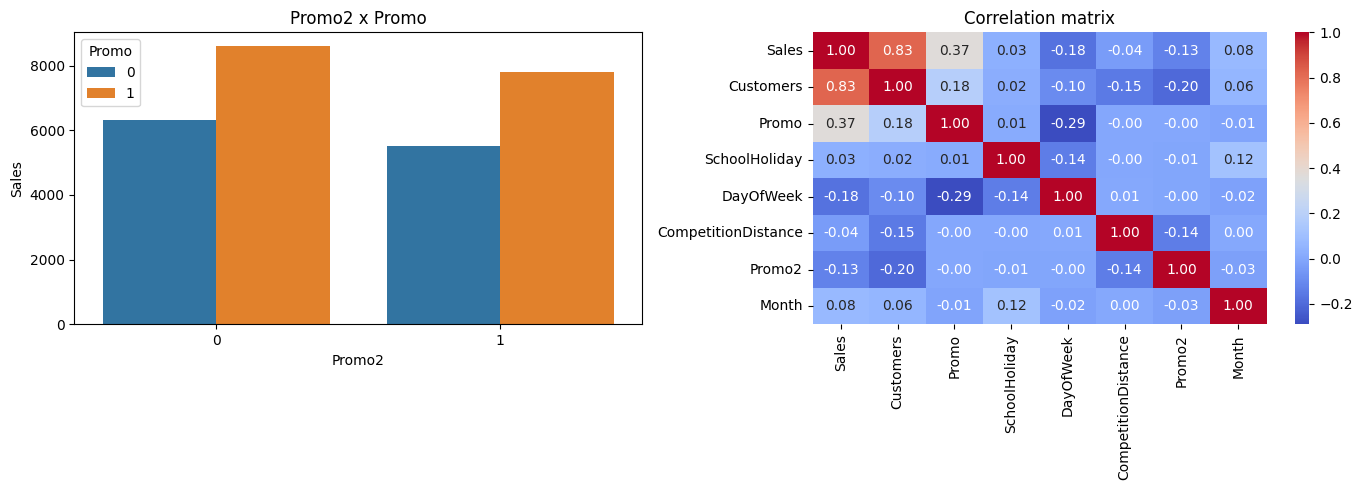

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=train_df, x="Promo2", y="Sales", hue="Promo", ax=ax[0], errorbar=None)
ax[0].set_title("Promo2 x Promo")

corr_cols = ["Sales", "Customers", "Promo", "SchoolHoliday", "DayOfWeek",
             "CompetitionDistance", "Promo2", "Month"]
sns.heatmap(train_df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1])
ax[1].set_title("Correlation matrix")
plt.tight_layout(); plt.show()

### Key EDA Insights
1. **Promotions are the strongest controllable driver**: average sales are ~39% higher on promo days (8,205 vs 5,907), correlation with Sales = 0.37.
2. **Strong seasonality**: weekly (Saturday lowest, Monday highest) and yearly (December peak in both 2013 and 2014), plus an upward trend in 2015. Calendar features are essential.
3. **Stores are very different from each other**: StoreType "b" averages ~10.2K vs ~6.8–6.9K for other types, so store-level information must be encoded.
4. **Competition distance and school holidays have a weak effect** (corr ≈ -0.04 and +4% sales), while Promo2 stores sell less on average (a store-group difference, not a causal effect).
5. **Customers correlates 0.83 with Sales but is unknown at forecast time**, so it is excluded to avoid leakage.

### Hypothesis to test
The promo effect may depend on the day of the week (interaction), which tree-based models can capture automatically.

## 4. Feature engineering & pipeline
### Feature engineering
- `CompetitionMonthsOpen`: months since the nearest competitor opened (0 if unknown).
- `Promo2WeeksOpen`: weeks since the store joined the extended promotion (0 if not enrolled).
- `IsPromo2Month`: whether the current month is one of the store's Promo2 renewal months.
- `IsWeekend`.
These use only information available in advance. Lag features were not used: the horizon is 6 weeks, so any lag would have to be at least 42 days old.

In [15]:
month_map = {1:"Jan",2:"Feb",3:"Mar",4:"Apr",5:"May",6:"Jun",
             7:"Jul",8:"Aug",9:"Sept",10:"Oct",11:"Nov",12:"Dec"}

def add_features(d):
    d = d.copy()
    d["CompetitionMonthsOpen"] = ((d["Year"] - d["CompetitionOpenSinceYear"]) * 12
                                  + (d["Month"] - d["CompetitionOpenSinceMonth"]))
    d["CompetitionMonthsOpen"] = d["CompetitionMonthsOpen"].clip(lower=0).fillna(0)
    d["Promo2WeeksOpen"] = ((d["Year"] - d["Promo2SinceYear"]) * 52
                            + (d["WeekOfYear"] - d["Promo2SinceWeek"]))
    d["Promo2WeeksOpen"] = d["Promo2WeeksOpen"].clip(lower=0).fillna(0)
    d["IsPromo2Month"] = [
        int(isinstance(pi, str) and month_map[m] in pi.split(","))
        for pi, m in zip(d["PromoInterval"], d["Month"])
    ]
    d["IsWeekend"] = (d["DayOfWeek"] >= 6).astype(int)
    d["StateHoliday"] = d["StateHoliday"].astype(str)
    return d

train_df, val_df, test_df = [add_features(d) for d in (train_df, val_df, test_df)]
train_df[["CompetitionMonthsOpen", "Promo2WeeksOpen", "IsPromo2Month"]].describe().T

,count,mean,std,min,25%,50%,75%,max
CompetitionMonthsOpen,766584.0,39.463739,50.801236,0.0,0.0,14.0,71.0,299.0
Promo2WeeksOpen,766584.0,53.471917,79.045892,0.0,0.0,0.0,102.0,300.0
IsPromo2Month,766584.0,0.171200,0.376684,0.0,0.0,0.0,0.0,1.0


### Preprocessing pipeline (scikit-learn)
Everything is inside one `Pipeline`/`ColumnTransformer`, fitted on the training data only:
- numeric columns: median imputation (scaling only for Ridge);
- categorical columns (`StoreType`, `Assortment`, `StateHoliday`): one-hot encoding, unknown categories ignored;
- `StoreMeanEncoder`: each store's mean log-sales, learned from the training data only, so it does not leak validation or test information.
`Year` is not used because tree models cannot extrapolate to unseen years.

In [16]:
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

class StoreMeanEncoder(BaseEstimator, TransformerMixin):
    """Mean log-sales per store, learned from the training data only."""
    def fit(self, X, y):
        s = pd.Series(np.asarray(y), index=X["Store"].values)
        self.means_ = s.groupby(level=0).mean()
        self.global_ = float(np.mean(y))
        return self
    def transform(self, X):
        return X["Store"].map(self.means_).fillna(self.global_).to_frame("StoreMeanLogSales")

num_cols = ["DayOfWeek", "Promo", "SchoolHoliday", "Promo2", "Month", "Day", "WeekOfYear",
            "CompetitionDistance", "CompetitionMonthsOpen", "Promo2WeeksOpen",
            "IsPromo2Month", "IsWeekend"]
cat_cols = ["StoreType", "Assortment", "StateHoliday"]

preprocessor = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("store", StoreMeanEncoder(), ["Store"]),
])

feature_cols = num_cols + cat_cols + ["Store"]
X_train, X_val, X_test = train_df[feature_cols], val_df[feature_cols], test_df[feature_cols]
y_train, y_val, y_test = (np.log1p(d["Sales"]) for d in (train_df, val_df, test_df))

print(X_train.shape, X_val.shape, X_test.shape)

(766584, 16) (37472, 16) (40282, 16)


## 5. Modeling
### Metric and baselines
RMSPE is computed on the original sales scale. Two baselines: the global mean, and each store's mean. Every model must beat the store-mean baseline.

In [17]:
def rmspe(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    m = y_true != 0
    return np.sqrt(np.mean(((y_true[m] - y_pred[m]) / y_true[m]) ** 2))

y_val_raw = np.expm1(y_val)

b1 = np.full(len(y_val), np.expm1(y_train.mean()))

store_mean = y_train.groupby(X_train["Store"]).mean()
b2 = np.expm1(X_val["Store"].map(store_mean).fillna(y_train.mean()))

results = pd.DataFrame({
    "Model": ["Baseline: global mean", "Baseline: store mean"],
    "RMSPE": [rmspe(y_val_raw, b1), rmspe(y_val_raw, b2)],
})
results

,Model,RMSPE
0,Baseline: global mean,0.471317
1,Baseline: store mean,0.279546


### Candidate models
Ridge (linear), Random Forest, HistGradientBoosting and XGBoost, all with default-ish settings, evaluated on the validation set.

In [18]:
import time
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor

linear_pre = ColumnTransformer([
    ("num", Pipeline([("imp", SimpleImputer(strategy="median")),
                      ("sc", StandardScaler())]), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("store", Pipeline([("enc", StoreMeanEncoder()), ("sc", StandardScaler())]), ["Store"]),
])

models = {
    "Ridge": Pipeline([("pre", linear_pre), ("model", Ridge(alpha=1.0))]),

    "Random Forest": Pipeline([("pre", preprocessor), ("model", RandomForestRegressor(
        n_estimators=100, min_samples_leaf=5, max_samples=0.3,
        n_jobs=-1, random_state=42))]),

    "HistGradientBoosting": Pipeline([("pre", preprocessor), ("model", HistGradientBoostingRegressor(
        max_iter=300, learning_rate=0.1, random_state=42))]),

    "XGBoost": Pipeline([("pre", preprocessor), ("model", XGBRegressor(
        n_estimators=300, learning_rate=0.1, max_depth=8,
        subsample=0.8, colsample_bytree=0.8, n_jobs=-1, random_state=42))]),
}

In [19]:
fitted = {}
rows = [("Baseline: global mean", rmspe(y_val_raw, b1), np.nan),
        ("Baseline: store mean",  rmspe(y_val_raw, b2), np.nan)]

for name, pipe in models.items():
    t0 = time.time()
    pipe.fit(X_train, y_train)
    pred = np.expm1(pipe.predict(X_val))
    fitted[name] = pipe
    rows.append((name, rmspe(y_val_raw, pred), round(time.time() - t0, 1)))
    print(f"{name:22s} RMSPE={rows[-1][1]:.4f}  ({rows[-1][2]}s)")

results = pd.DataFrame(rows, columns=["Model", "Val RMSPE", "Train time (s)"]).sort_values("Val RMSPE")
results

Ridge                  RMSPE=0.2140  (1.9s)
Random Forest          RMSPE=0.1420  (194.7s)
HistGradientBoosting   RMSPE=0.1563  (44.2s)
XGBoost                RMSPE=0.1432  (36.7s)


,Model,Val RMSPE,Train time (s)
3,Random Forest,0.141954,194.7
5,XGBoost,0.143189,36.7
4,HistGradientBoosting,0.156336,44.2
2,Ridge,0.214023,1.9
1,Baseline: store mean,0.279546,NaN
0,Baseline: global mean,0.471317,NaN


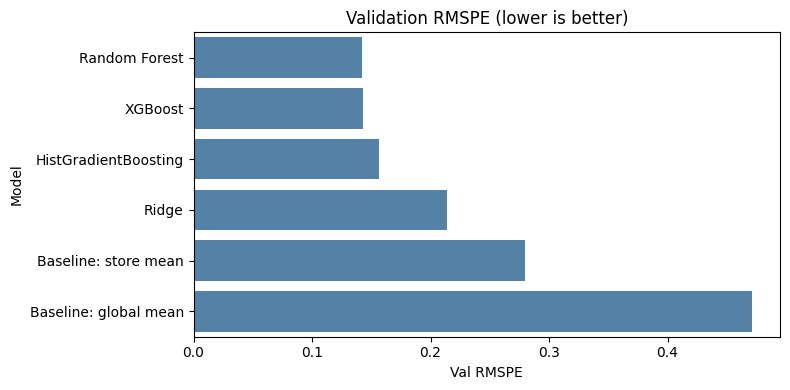

In [20]:
plt.figure(figsize=(8, 4))
sns.barplot(data=results, y="Model", x="Val RMSPE", color="steelblue")
plt.title("Validation RMSPE (lower is better)")
plt.tight_layout(); plt.show()

**Result.** All models beat the baselines. Ridge (0.214) is far behind the tree models, so the relationships are non-linear (for example promo × day of week). Random Forest and XGBoost are almost tied (0.1420 vs 0.1432), but XGBoost trains about 5× faster.

## 6. Tuning & cross-validation
### Time-series cross-validation
Three folds, each trained on the past and validated on the following 42 days (the training data only; the validation and test sets are not used here). The training data is sorted by date first.

In [21]:
train_df = train_df.sort_values("Date").reset_index(drop=True)
X_train = train_df[feature_cols]
y_train = np.log1p(train_df["Sales"])
print(train_df["Date"].is_monotonic_increasing, X_train.shape)

True (766584, 16)


In [22]:
horizon = pd.Timedelta(days=42)
last = train_df["Date"].max()

cv_splits = []
for k in [3, 2, 1]:
    val_end = last - horizon * (k - 1)
    val_start = val_end - horizon + pd.Timedelta(days=1)
    tr_idx = np.where(train_df["Date"] < val_start)[0]
    va_idx = np.where((train_df["Date"] >= val_start) & (train_df["Date"] <= val_end))[0]
    cv_splits.append((tr_idx, va_idx))
    print(f"fold: train → {train_df['Date'].iloc[tr_idx].max().date()} | "
          f"val {val_start.date()} → {val_end.date()}  ({len(tr_idx):,} / {len(va_idx):,})")

fold: train → 2015-01-02 | val 2015-01-03 → 2015-02-13  (649,442 / 39,923)
fold: train → 2015-02-13 | val 2015-02-14 → 2015-03-27  (689,365 / 40,175)
fold: train → 2015-03-27 | val 2015-03-28 → 2015-05-08  (729,540 / 37,044)


### Randomized hyperparameter search
Scorer: RMSPE on the original sales scale. 10 random configurations for XGBoost and 8 for HistGradientBoosting (30 and 24 fits). Random Forest was not tuned: one fit takes ~3 minutes and the saved model is 141 MB.

In [23]:
from sklearn.model_selection import RandomizedSearchCV

def rmspe_scorer(est, X, y):
    return -rmspe(np.expm1(y), np.expm1(est.predict(X)))

def run_search(name, pipe, param_dist, n_iter):
    t0 = time.time()
    search = RandomizedSearchCV(pipe, param_dist, n_iter=n_iter, cv=cv_splits,
                                scoring=rmspe_scorer, random_state=42, n_jobs=1,
                                refit=True, verbose=1)
    search.fit(X_train, y_train)
    pred = np.expm1(search.predict(X_val))
    print(f"\n{name}: CV RMSPE={-search.best_score_:.4f} | Val RMSPE={rmspe(y_val_raw, pred):.4f} "
          f"| {time.time()-t0:.0f}s")
    print("Best params:", search.best_params_)
    return search

xgb_params = {
    "model__n_estimators":     [300, 500, 800],
    "model__learning_rate":    [0.03, 0.05, 0.1],
    "model__max_depth":        [6, 8, 10],
    "model__min_child_weight": [1, 5, 10],
    "model__subsample":        [0.7, 0.8, 0.9],
    "model__colsample_bytree": [0.6, 0.8, 1.0],
}
xgb_search = run_search("XGBoost", models["XGBoost"], xgb_params, n_iter=10)

Fitting 3 folds for each of 10 candidates, totalling 30 fits

XGBoost: CV RMSPE=0.1753 | Val RMSPE=0.1363 | 1733s
Best params: {'model__subsample': 0.8, 'model__n_estimators': 500, 'model__min_child_weight': 5, 'model__max_depth': 10, 'model__learning_rate': 0.05, 'model__colsample_bytree': 0.6}


In [24]:
hgb_params = {
    "model__max_iter":          [300, 500, 800],
    "model__learning_rate":     [0.05, 0.1, 0.2],
    "model__max_leaf_nodes":    [31, 63, 127],
    "model__min_samples_leaf":  [20, 50, 100],
    "model__l2_regularization": [0, 1, 10],
}
hgb_search = run_search("HistGradientBoosting", models["HistGradientBoosting"], hgb_params, n_iter=8)

Fitting 3 folds for each of 8 candidates, totalling 24 fits

HistGradientBoosting: CV RMSPE=0.1749 | Val RMSPE=0.1378 | 2107s
Best params: {'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 63, 'model__max_iter': 800, 'model__learning_rate': 0.2, 'model__l2_regularization': 10}


In [25]:
def cv_report(name, search):
    cv = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
    best = cv.iloc[0]
    folds = [round(-best[f"split{i}_test_score"], 4) for i in range(3)]
    print(f"{name} best config, per-fold RMSPE: {folds}")
    cols = ["rank_test_score", "mean_test_score", "std_test_score"]
    return cv[cols + ["params"]].head(3).assign(mean_test_score=lambda d: -d["mean_test_score"])

display(cv_report("XGBoost", xgb_search))
display(cv_report("HGB", hgb_search))

XGBoost best config, per-fold RMSPE: [np.float64(0.1822), np.float64(0.184), np.float64(0.1596)]


,rank_test_score,mean_test_score,std_test_score,params
1,1,0.175267,0.011132,"{'model__subsample': 0.8, 'model__n_estimators..."
6,2,0.176802,0.013111,"{'model__subsample': 0.7, 'model__n_estimators..."
2,3,0.178849,0.014660,"{'model__subsample': 0.9, 'model__n_estimators..."


HGB best config, per-fold RMSPE: [np.float64(0.1847), np.float64(0.1777), np.float64(0.1624)]


,rank_test_score,mean_test_score,std_test_score,params
4,1,0.174941,0.009338,"{'model__min_samples_leaf': 50, 'model__max_le..."
7,2,0.175795,0.010117,"{'model__min_samples_leaf': 20, 'model__max_le..."
0,3,0.178974,0.011466,"{'model__min_samples_leaf': 20, 'model__max_le..."


In [26]:
rows = [("Baseline: store mean", np.nan, rmspe(y_val_raw, b2)),
        ("Baseline: global mean", np.nan, rmspe(y_val_raw, b1))]
for name, est in fitted.items():
    rows.append((f"{name} (default)", np.nan, rmspe(y_val_raw, np.expm1(est.predict(X_val)))))
for name, s in [("XGBoost (tuned)", xgb_search), ("HistGradientBoosting (tuned)", hgb_search)]:
    rows.append((name, -s.best_score_, rmspe(y_val_raw, np.expm1(s.predict(X_val)))))

summary = pd.DataFrame(rows, columns=["Model", "CV RMSPE", "Val RMSPE"]).sort_values("Val RMSPE")
summary.round(4)

,Model,CV RMSPE,Val RMSPE
6,XGBoost (tuned),0.1753,0.1363
7,HistGradientBoosting (tuned),0.1749,0.1378
3,Random Forest (default),NaN,0.1420
5,XGBoost (default),NaN,0.1432
4,HistGradientBoosting (default),NaN,0.1563
2,Ridge (default),NaN,0.2140
0,Baseline: store mean,NaN,0.2795
1,Baseline: global mean,NaN,0.4713


In [27]:
import joblib, os
for name, est in [("xgb_tuned", xgb_search.best_estimator_),
                  ("hgb_tuned", hgb_search.best_estimator_),
                  ("random_forest", fitted["Random Forest"])]:
    path = f"/content/{name}.joblib"
    joblib.dump(est, path, compress=3)
    print(f"{name:15s} {os.path.getsize(path)/1e6:.1f} MB")

xgb_tuned       11.8 MB
hgb_tuned       2.6 MB
random_forest   141.5 MB


**Results**
| Model | CV RMSPE | Val RMSPE |
|---|---|---|
| XGBoost (tuned) | 0.1753 | **0.1363** |
| HistGradientBoosting (tuned) | 0.1749 | 0.1378 |
| Random Forest (default) | n/a | 0.1420 |

Tuning improved XGBoost from 0.1432 to 0.1363 and HistGradientBoosting from 0.1563 to 0.1378. The CV scores of the two tuned models differ by 0.0004, within noise. Per-fold scores (XGBoost 0.182 / 0.184 / 0.160) show the model is fairly stable. Several best values sit at the edge of the search grid, so more tuning could help.

**Chosen model: tuned XGBoost.** Best validation RMSPE, CV on par with the best alternative, and a deployable size (11.8 MB vs 141.5 MB for Random Forest).

## 7. Final evaluation on the untouched test set
The chosen configuration is retrained on train + validation and scored once on the test set (2015-06-20 → 2015-07-31). Baseline for comparison: store mean, computed from the same data.

In [28]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X_full = pd.concat([X_train, X_val]); y_full = pd.concat([y_train, y_val])
final_model = clone(xgb_search.best_estimator_).fit(X_full, y_full)

y_test_raw = np.expm1(y_test).values
pred_test = np.expm1(final_model.predict(X_test))

sm = y_full.groupby(X_full["Store"]).mean()
base_test = np.expm1(X_test["Store"].map(sm).fillna(y_full.mean()))

test_results = pd.DataFrame({
    "Model": ["Baseline: store mean", "XGBoost (final)"],
    "RMSPE": [rmspe(y_test_raw, base_test), rmspe(y_test_raw, pred_test)],
    "MAE":   [mean_absolute_error(y_test_raw, base_test), mean_absolute_error(y_test_raw, pred_test)],
    "RMSE":  [np.sqrt(mean_squared_error(y_test_raw, base_test)), np.sqrt(mean_squared_error(y_test_raw, pred_test))],
    "R²":    [r2_score(y_test_raw, base_test), r2_score(y_test_raw, pred_test)],
}).round(4)
test_results

,Model,RMSPE,MAE,RMSE,R²
0,Baseline: store mean,0.3041,1440.8458,1954.6308,0.5906
1,XGBoost (final),0.1231,635.1012,925.2500,0.9083


| Model | RMSPE | MAE | RMSE | R² |
|---|---|---|---|---|
| Baseline: store mean | 0.3041 | 1,441 | 1,955 | 0.591 |
| XGBoost (tuned, final) | **0.1231** | **635** | **925** | **0.908** |

The model cuts the percentage error from 30.4% to 12.3% versus a per-store average and explains about 91% of the variance in daily sales. The test score (0.1231) is better than the validation score (0.1363); the test window contains no state holidays, which may make it easier.

Mean % error (bias): -0.0164

RMSPE by DayOfWeek:
DayOfWeek
1    0.116
2    0.108
3    0.113
4    0.120
5    0.121
6    0.154
7    0.145

RMSPE by Promo:
Promo
0    0.129
1    0.115

RMSPE by StoreType:
StoreType
a    0.127
b    0.119
c    0.124
d    0.116

RMSPE by StateHoliday:
StateHoliday
0    0.123

Worst 10 stores (RMSPE):
 Store
292    1.104
909    0.761
782    0.492
876    0.475
722    0.307
534    0.278
956    0.258
274    0.257
554    0.249
675    0.240


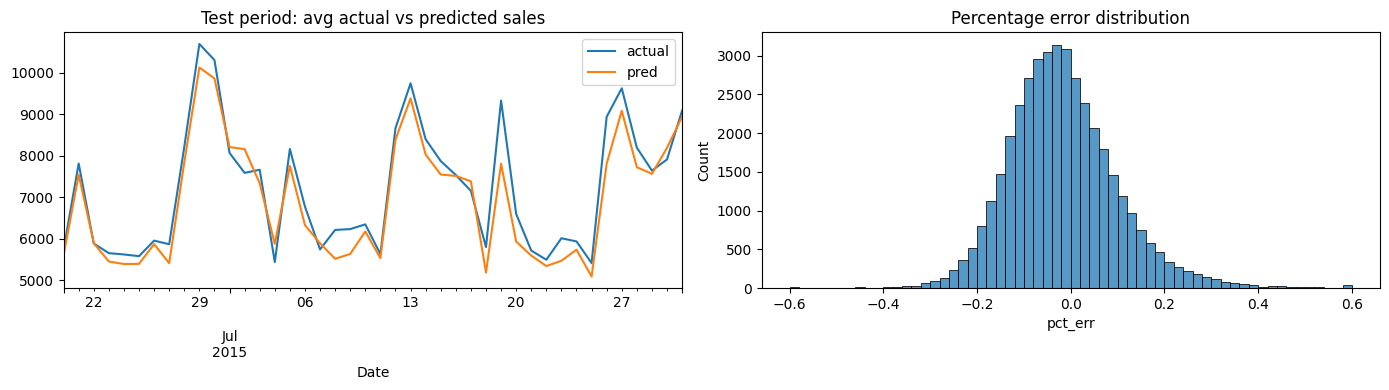

In [29]:
err = test_df[["Store", "Date", "DayOfWeek", "Promo", "StoreType", "StateHoliday"]].copy()
err["actual"], err["pred"] = y_test_raw, pred_test
err["pct_err"] = (err["pred"] - err["actual"]) / err["actual"]
err["sq_pct"] = err["pct_err"] ** 2

print("Mean % error (bias):", round(err["pct_err"].mean(), 4))
for col in ["DayOfWeek", "Promo", "StoreType", "StateHoliday"]:
    print(f"\nRMSPE by {col}:")
    print(err.groupby(col)["sq_pct"].mean().pow(0.5).round(3).to_string())

worst = err.groupby("Store")["sq_pct"].mean().pow(0.5).sort_values(ascending=False).head(10)
print("\nWorst 10 stores (RMSPE):\n", worst.round(3).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
daily = err.groupby("Date")[["actual", "pred"]].mean()
daily.plot(ax=ax[0]); ax[0].set_title("Test period: avg actual vs predicted sales")
sns.histplot(err["pct_err"].clip(-0.6, 0.6), bins=60, ax=ax[1])
ax[1].set_title("Percentage error distribution")
plt.tight_layout(); plt.show()

### Error analysis
- **Bias:** slight under-prediction (mean error −1.6%), most visible at demand peaks.
- **Day of week:** weekends are harder (Saturday 0.154, Sunday 0.145 vs ~0.11 on Tuesday).
- **Balanced across segments:** store types 0.116–0.127; promo / no-promo days 0.115 / 0.129.
- **Holidays not tested:** the test window contains no state holidays.

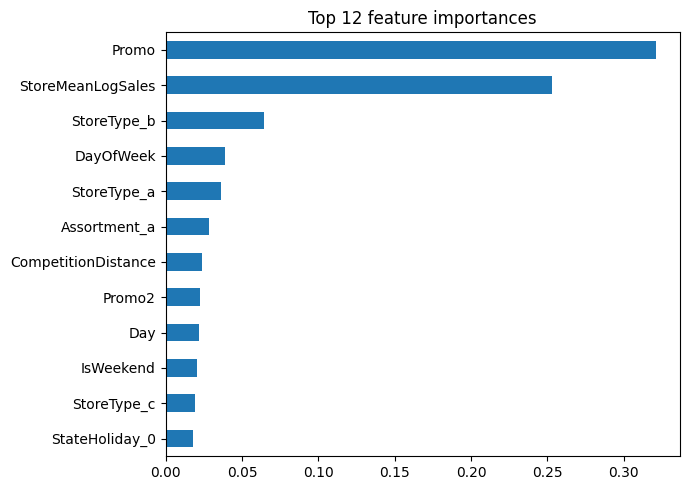

In [30]:
pre = final_model.named_steps["pre"]
names = num_cols + list(pre.named_transformers_["cat"].get_feature_names_out(cat_cols)) + ["StoreMeanLogSales"]
imp = pd.Series(final_model.named_steps["model"].feature_importances_, index=names).sort_values(ascending=False)
imp.head(12).iloc[::-1].plot.barh(figsize=(7, 5), title="Top 12 feature importances")
plt.tight_layout(); plt.show()

### What drives the predictions
Promo (about 0.32) and the store's historical average (about 0.25) account for more than half of the total feature importance, followed by store type, day of week and assortment. This is the model's internal importance, not a causal effect.

### Looking closer at the worst stores

In [31]:
bad = [292, 909, 782, 876]
print(store[store["Store"].isin(bad)].to_string(index=False))

for s in bad:
    tr = train_df[train_df["Store"] == s]
    recent = tr[tr["Date"] >= tr["Date"].max() - pd.Timedelta(days=56)]
    d = err[err["Store"] == s]
    print(f"\nStore {s}: train mean={tr['Sales'].mean():.0f} | last 8 weeks of train={recent['Sales'].mean():.0f} "
          f"| test actual={d['actual'].mean():.0f} | test pred={d['pred'].mean():.0f} | test days={len(d)}")

 Store StoreType Assortment  CompetitionDistance  CompetitionOpenSinceMonth  CompetitionOpenSinceYear  Promo2  Promo2SinceWeek  Promo2SinceYear   PromoInterval
   292         a          a               1100.0                        6.0                    2009.0       0              NaN              NaN             NaN
   782         c          c               5390.0                        8.0                    2003.0       1              1.0           2012.0 Jan,Apr,Jul,Oct
   876         a          a              21790.0                        4.0                    2005.0       1             18.0           2015.0 Feb,May,Aug,Nov
   909         a          c               1680.0                        NaN                       NaN       1             45.0           2009.0 Feb,May,Aug,Nov

Store 292: train mean=5717 | last 8 weeks of train=6256 | test actual=7328 | test pred=5437 | test days=18

Store 909: train mean=10495 | last 8 weeks of train=11424 | test actual=15828 | test pred=1

### How much do the worst stores matter?

In [32]:
store_rmspe = err.groupby("Store")["sq_pct"].mean().pow(0.5)
top10 = store_rmspe.sort_values(ascending=False).head(10).index
mask = ~err["Store"].isin(top10)

print("RMSPE (all stores):            ", round(np.sqrt(err["sq_pct"].mean()), 4))
print("RMSPE (without worst 10):      ", round(np.sqrt(err.loc[mask, "sq_pct"].mean()), 4))
print("Median per-store RMSPE:        ", round(store_rmspe.median(), 4))
print("Stores with RMSPE > 0.20:      ", (store_rmspe > 0.20).sum(), "of", len(store_rmspe))

RMSPE (all stores):             0.1231
RMSPE (without worst 10):       0.117
Median per-store RMSPE:         0.1085
Stores with RMSPE > 0.20:       29 of 1115


- **Store-level outliers:** the median store has RMSPE 0.109 and 29 of 1,115 stores (2.6%) are above 0.20. Removing the 10 worst stores moves the overall RMSPE only from 0.1231 to 0.117, so the result is not driven by a few bad stores.
- **Under-predicted stores:** for stores 292, 909 and 876, actual test sales were about 35%, 52% and 23% above the prediction, and above their own recent level. The available features do not capture such a jump. Store 782 is different: its average level is within 3%, but day-level errors are large.

### What-if: promotion effect
We flip `Promo` on and off for the same stores and dates and compare the model's predictions. This isolates what the model attributes to promotions, holding store and calendar fixed. It is an association learned from the data, not a proven causal effect.

In [33]:
def predict_with_promo(p):
    X = X_test.copy()
    X["Promo"] = p
    return np.expm1(final_model.predict(X))

p_on, p_off = predict_with_promo(1), predict_with_promo(0)
print(f"Model-implied promo uplift (same stores/days): {(p_on.sum()/p_off.sum()-1)*100:.1f}%")

whatif = pd.DataFrame({"DayOfWeek": X_test["DayOfWeek"].values, "on": p_on, "off": p_off})
print((whatif.groupby("DayOfWeek")[["on", "off"]].sum().pipe(lambda d: (d["on"]/d["off"]-1)*100)).round(1))

act = test_df.groupby("Promo")["Sales"].mean()
print("\nActual avg sales in test by Promo:\n", act.round(0))

Model-implied promo uplift (same stores/days): 31.4%
DayOfWeek
1    46.400002
2    36.900002
3    29.500000
4    27.100000
5    22.600000
6    25.799999
7    10.600000
dtype: float32

Actual avg sales in test by Promo:
 Promo
0    5905.0
1    8494.0
Name: Sales, dtype: float64


**Sanity check.** The per-day uplifts for Saturday and Sunday in the previous output look suspicious, so we check whether promotions ever run on weekends.

In [34]:
print(train_df.groupby("DayOfWeek")["Promo"].agg(["mean", "sum"]).round(3))

            mean    sum
DayOfWeek              
1          0.563  70557
2          0.539  70429
3          0.541  69567
4          0.554  68116
5          0.523  65469
6          0.000      0
7          0.000      0


**Finding:** promotions run only Monday–Friday (`Promo` is 0 on every Saturday and Sunday in the training data). The model has never seen a weekend promotion, so its weekend uplift values (Saturday +26%, Sunday +11%) are extrapolation and must be ignored. We recompute the uplift on weekdays only.

In [35]:
wk = (X_test["DayOfWeek"] <= 5).values
print(f"Model-implied promo uplift, Mon–Fri only: {(p_on[wk].sum()/p_off[wk].sum()-1)*100:.1f}%")

act_wk = test_df[test_df["DayOfWeek"] <= 5].groupby("Promo")["Sales"].mean()
print("\nActual avg sales Mon–Fri in test by Promo:\n", act_wk.round(0))

Model-implied promo uplift, Mon–Fri only: 32.6%

Actual avg sales Mon–Fri in test by Promo:
 Promo
0    5980.0
1    8494.0
Name: Sales, dtype: float64


**Result.** On weekdays the model implies a promo uplift of about +33%, compared with +42% in the raw averages (8,494 vs 5,980). The raw gap is larger because it also reflects differences between the stores and days that happen to have promotions; the model compares the same store and day with and without a promotion. Largest uplift on Monday (+46%), smallest on Friday (+23%).
**Hypothesis check:** the EDA hypothesis holds. The promo effect depends on the day of the week, which the tree model captures through interactions.

## 8. Business insight
**What the results mean.** On unseen data, forecasts are on average about 12% off per store-day (RMSPE 0.123, MAE ≈ 635 per store-day), compared with 30% for a simple per-store average.

**Promotions.** Promotions run only Monday–Friday. In the test period, weekday promo days averaged 8,494 vs 5,980 on non-promo weekdays (+42%). Holding store and calendar fixed, the model implies about +33%, largest on Monday (+46%) and smallest on Friday (+23%). Weekend promo effects cannot be estimated because no weekend promotions exist in the data.

**Recommendations**
1. Use the forecast for staffing and stock planning on a 6-week horizon. Expect about ±12% error per store-day and keep a safety buffer on peak days, since the model slightly under-predicts (−1.6%).
2. Put the ~29 stores with RMSPE above 0.20 on a manual-review list.
3. Test promo timing with a controlled experiment before moving budget: the model suggests early-week promos lift sales most, but this is an association, not proven causation.
4. Retrain regularly (for example monthly) as new sales arrive.

### Limitations
- One 6-week test window (June–July 2015, no state holidays): holiday and December-peak accuracy were not evaluated, and the CV folds only cover January–May 2015.
- 180 stores have no records between July and December 2014; these gaps were not imputed.
- No lag or rolling sales features and no weather or local events, so store-specific shocks (e.g. stores 292, 909, 876) are missed.
- The hyperparameter search was small (10 and 8 random configurations) and several best values sit at the edge of the grid.
- Promo effects are model-based associations, and forecasts need the promo calendar to be known in advance.
- No promotions occur on weekends in the data, so the what-if tool is limited to weekdays.
- Predictions are for open days only.

## 9. Deployment preparation
`joblib` stores the class name of custom transformers, so `StoreMeanEncoder` is moved into its own file (`store_encoder.py`) that the app can import. The final model is retrained with the same hyperparameters and must reproduce the test RMSPE (≈ 0.1231) before we save it. Saved files: `model.joblib`, `store_encoder.py`, `store_info.csv`. Loading is tested in a fresh Python process.

In [36]:
%%writefile store_encoder.py
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin

class StoreMeanEncoder(BaseEstimator, TransformerMixin):
    """Mean log-sales per store, learned from the training data only."""
    def fit(self, X, y):
        s = pd.Series(np.asarray(y), index=X["Store"].values)
        self.means_ = s.groupby(level=0).mean()
        self.global_ = float(np.mean(y))
        return self

    def transform(self, X):
        return X["Store"].map(self.means_).fillna(self.global_).to_frame("StoreMeanLogSales")

Writing store_encoder.py


In [37]:
from store_encoder import StoreMeanEncoder as SME

pre_app = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("store", SME(), ["Store"]),
])
best_xgb_params = xgb_search.best_estimator_.named_steps["model"].get_params()
app_model = Pipeline([("pre", pre_app), ("model", XGBRegressor(**best_xgb_params))])
app_model.fit(X_full, y_full)

pred_app = np.expm1(app_model.predict(X_test))
print("Test RMSPE (app_model):", round(rmspe(y_test_raw, pred_app), 4), "| expected ≈ 0.1231")

Test RMSPE (app_model): 0.1231 | expected ≈ 0.1231


In [38]:
import shutil
os.makedirs("app", exist_ok=True)
joblib.dump(app_model, "app/model.joblib", compress=3)
shutil.copy("store_encoder.py", "app/store_encoder.py")

store_cols = ["Store", "StoreType", "Assortment", "CompetitionDistance",
              "CompetitionOpenSinceMonth", "CompetitionOpenSinceYear",
              "Promo2", "Promo2SinceWeek", "Promo2SinceYear", "PromoInterval"]
store[store_cols].to_csv("app/store_info.csv", index=False)
print("model size:", round(os.path.getsize("app/model.joblib") / 1e6, 1), "MB")

model size: 12.0 MB


In [39]:
!cd app && python -c "import joblib; m = joblib.load('model.joblib'); print('loaded OK:', type(m).__name__)"

loaded OK: Pipeline


### App feature builder
The app receives only a store, dates and a promo choice, so `features.py` rebuilds the same 16 model inputs from `store_info.csv` using the same logic as the notebook. To make sure the app cannot silently diverge from the notebook, the function is tested against `test_df`: features and predictions must be identical for several stores.

In [40]:
%%writefile app/features.py
import numpy as np
import pandas as pd

MONTH_MAP = {1: "Jan", 2: "Feb", 3: "Mar", 4: "Apr", 5: "May", 6: "Jun",
             7: "Jul", 8: "Aug", 9: "Sept", 10: "Oct", 11: "Nov", 12: "Dec"}

NUM_COLS = ["DayOfWeek", "Promo", "SchoolHoliday", "Promo2", "Month", "Day", "WeekOfYear",
            "CompetitionDistance", "CompetitionMonthsOpen", "Promo2WeeksOpen",
            "IsPromo2Month", "IsWeekend"]
CAT_COLS = ["StoreType", "Assortment", "StateHoliday"]
FEATURE_COLS = NUM_COLS + CAT_COLS + ["Store"]


def build_features(store_row, dates, promo=0, school_holiday=0, state_holiday="0"):
    """Build the model input for one store and a list of dates.

    promo / school_holiday / state_holiday can be a single value or one value per date.
    Promotions never run on weekends in the training data, so Promo is forced to 0 there.
    """
    d = pd.DataFrame({"Date": pd.to_datetime(list(dates))})
    d["Store"] = int(store_row["Store"])
    d["DayOfWeek"] = d["Date"].dt.dayofweek + 1
    d["Year"] = d["Date"].dt.year
    d["Month"] = d["Date"].dt.month
    d["Day"] = d["Date"].dt.day
    d["WeekOfYear"] = d["Date"].dt.isocalendar().week.astype(int)

    d["Promo"] = np.where(d["DayOfWeek"] <= 5, promo, 0).astype(int)
    d["SchoolHoliday"] = school_holiday
    d["StateHoliday"] = state_holiday
    d["StateHoliday"] = d["StateHoliday"].astype(str)

    for c in ["StoreType", "Assortment", "CompetitionDistance", "Promo2"]:
        d[c] = store_row[c]

    # same cleaning as the notebook: implausible competition years -> missing
    comp_year = store_row["CompetitionOpenSinceYear"]
    if pd.notna(comp_year) and comp_year < 1990:
        comp_year = np.nan
    comp_month = store_row["CompetitionOpenSinceMonth"]

    d["CompetitionMonthsOpen"] = ((d["Year"] - comp_year) * 12 + (d["Month"] - comp_month)
                                  ).clip(lower=0).fillna(0)
    d["Promo2WeeksOpen"] = ((d["Year"] - store_row["Promo2SinceYear"]) * 52
                            + (d["WeekOfYear"] - store_row["Promo2SinceWeek"])
                            ).clip(lower=0).fillna(0)

    interval = store_row["PromoInterval"]
    d["IsPromo2Month"] = [int(isinstance(interval, str) and MONTH_MAP[m] in interval.split(","))
                          for m in d["Month"]]
    d["IsWeekend"] = (d["DayOfWeek"] >= 6).astype(int)
    return d[FEATURE_COLS]

Writing app/features.py


In [41]:
import sys
sys.path.insert(0, "app")
from features import build_features, FEATURE_COLS

store_info = pd.read_csv("app/store_info.csv").set_index("Store", drop=False)
app_model_loaded = joblib.load("app/model.joblib")

for s in [1, 292, 815, 909, 782]:
    mask = (test_df["Store"] == s).values
    rows = test_df[mask]
    if rows.empty:
        print(f"store {s}: no open days in test, skipped")
        continue
    mine = build_features(store_info.loc[s], rows["Date"].values,
                          promo=rows["Promo"].values,
                          school_holiday=rows["SchoolHoliday"].values,
                          state_holiday=rows["StateHoliday"].values)
    pd.testing.assert_frame_equal(mine.reset_index(drop=True),
                                  rows[FEATURE_COLS].reset_index(drop=True),
                                  check_dtype=False)
    same_pred = np.allclose(np.expm1(app_model_loaded.predict(mine)), pred_app[mask])
    print(f"store {s}: features identical, predictions identical = {same_pred} ({len(rows)} days)")

store 1: features identical, predictions identical = True (36 days)
store 292: features identical, predictions identical = True (18 days)
store 815: features identical, predictions identical = True (36 days)
store 909: features identical, predictions identical = True (22 days)
store 782: features identical, predictions identical = True (36 days)


**Result.** For five stores (including the outliers 292, 815 and 909), the app's features and predictions are identical to the notebook's. In a 14-day demo forecast for store 1, weekend values are the same with and without promotion (no weekend promotions exist in the data), while Monday–Friday forecasts are higher with a promotion.

In [42]:
future = pd.date_range("2015-08-03", periods=14)   # a Monday to the Sunday after next
row = store_info.loc[1]

with_promo = np.expm1(app_model_loaded.predict(build_features(row, future, promo=1)))
no_promo   = np.expm1(app_model_loaded.predict(build_features(row, future, promo=0)))

out = pd.DataFrame({"date": future.date, "day": future.day_name().str[:3],
                    "no_promo": no_promo.round(0), "with_promo": with_promo.round(0)})
out

,date,day,no_promo,with_promo
0,2015-08-03,Mon,4492.0,6183.0
1,2015-08-04,Tue,3885.0,5277.0
2,2015-08-05,Wed,3856.0,4830.0
3,2015-08-06,Thu,3760.0,4598.0
4,2015-08-07,Fri,3890.0,4613.0
5,2015-08-08,Sat,3723.0,3723.0
6,2015-08-09,Sun,3335.0,3335.0
7,2015-08-10,Mon,4198.0,5900.0
8,2015-08-11,Tue,3731.0,5120.0
9,2015-08-12,Wed,3685.0,4848.0


In [43]:
# 1) copy to Drive
!cp -r app "/content/drive/MyDrive/NextGen_Final_Project/"

# 2) download to your computer
!zip -r app.zip app
from google.colab import files
files.download("app.zip")

  adding: app/ (stored 0%)
  adding: app/features.py (deflated 60%)
  adding: app/store_encoder.py (deflated 45%)
  adding: app/__pycache__/ (stored 0%)
  adding: app/__pycache__/store_encoder.cpython-313.pyc (deflated 39%)
  adding: app/__pycache__/features.cpython-313.pyc (deflated 42%)
  adding: app/model.joblib (deflated 7%)
  adding: app/store_info.csv (deflated 80%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [44]:
open_rates = (df.groupby(["Store", "DayOfWeek"])["Open"].mean().round(3)
                .rename("open_rate").reset_index())
open_rates.to_csv("app/store_open_rates.csv", index=False)
print(open_rates.groupby("DayOfWeek")["open_rate"].mean().round(2))

DayOfWeek
1    0.95
2    0.99
3    0.97
4    0.92
5    0.95
6    1.00
7    0.02
Name: open_rate, dtype: float64


In [45]:
%%writefile app/app.py
import sys
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import streamlit as st

APP_DIR = Path(__file__).parent
sys.path.insert(0, str(APP_DIR))
from features import build_features  # noqa: E402

st.set_page_config(page_title="Store Sales Forecast", page_icon="🛒", layout="wide")

LAST_DATA_DAY = pd.Timestamp("2015-07-31")
TYPICAL_ERROR = 0.12   # test RMSPE ≈ 0.123


@st.cache_resource
def load_model():
    return joblib.load(APP_DIR / "model.joblib")


@st.cache_data
def load_store_info():
    return pd.read_csv(APP_DIR / "store_info.csv").set_index("Store", drop=False)


@st.cache_data
def load_open_rates():
    return pd.read_csv(APP_DIR / "store_open_rates.csv")


model = load_model()
stores = load_store_info()
rates = load_open_rates()

st.title("🛒 Store Sales Forecast")
st.write("Pick a store and a period to see the forecasted daily sales, and compare "
         "running promotions on weekdays with not running them.")

# ---------------- inputs ----------------
with st.sidebar:
    st.header("Scenario")
    store_id = st.selectbox("Store", stores.index.tolist())
    start = st.date_input("First day", value=pd.Timestamp("2015-08-03").date(),
                          min_value=pd.Timestamp("2015-08-01").date(),
                          max_value=pd.Timestamp("2016-12-31").date())
    days = st.slider("Number of days", 7, 42, 28)
    promo_on = st.toggle("Run promotions on weekdays", value=True)
    st.caption("Promotions never run on Saturday or Sunday in the historical data, "
               "so weekends are always forecast without a promotion.")

row = stores.loc[store_id]
dates = pd.date_range(pd.Timestamp(start), periods=days)

if dates[-1] > LAST_DATA_DAY + pd.Timedelta(days=42):
    st.warning("The model was built for a 6-week horizon after the last data (31 Jul 2015). "
               "Forecasts further out are less reliable.")

# ---------------- forecast ----------------
open_rate = rates[rates["Store"] == store_id].set_index("DayOfWeek")["open_rate"]
usually_closed = np.array([open_rate.get(d, 1.0) < 0.5 for d in (dates.dayofweek + 1)])


def forecast(promo):
    pred = np.expm1(model.predict(build_features(row, dates, promo=promo)))
    return np.where(usually_closed, 0.0, pred)


base = forecast(0)
plan = forecast(1) if promo_on else base

# ---------------- results ----------------
c1, c2, c3 = st.columns(3)
c1.metric("Forecast total sales", f"{plan.sum():,.0f}")
c2.metric("Open days in period", int((~usually_closed).sum()))
if promo_on and base.sum() > 0:
    gain = plan.sum() - base.sum()
    c3.metric("Gain vs. no promotion", f"{gain:,.0f}", f"{gain / base.sum() * 100:+.1f}%")
else:
    c3.metric("Gain vs. no promotion", "-")

chart_df = pd.DataFrame({"No promotion": base}, index=dates)
if promo_on:
    chart_df["Weekday promotions"] = plan
st.subheader(f"Daily forecast, store {store_id}")
st.line_chart(chart_df)

with st.expander("Daily numbers"):
    note = np.where(usually_closed, "usually closed, forecast 0",
                    np.where(promo_on & (dates.dayofweek < 5), "promo day", ""))
    st.dataframe(pd.DataFrame({"Date": dates.date, "Day": dates.day_name(),
                               "Forecast": plan.round(0), "Note": note}),
                 hide_index=True, use_container_width=True)

with st.expander("About this store"):
    dist = row["CompetitionDistance"]
    st.write(f"Store type **{row['StoreType']}**, assortment **{row['Assortment']}**, "
             f"nearest competitor: {'unknown' if pd.isna(dist) else f'{dist:,.0f} m'}.")

st.info(f"Typical error is about ±{TYPICAL_ERROR:.0%} per store-day (RMSPE 0.123 on a held-out "
        "6-week test). The promotion gain is what the model attributes to promotions, "
        "not a proven causal effect. Holidays were not evaluated, and stores with unusual "
        "jumps in sales can be under-predicted.")
st.caption("Data: Rossmann Store Sales (Kaggle). Model: XGBoost trained on 2013 – mid-2015.")

Writing app/app.py


In [49]:
!pip install -q streamlit
from streamlit.testing.v1 import AppTest

APP_PATH = "/content/app/app.py"
at = AppTest.from_file(APP_PATH, default_timeout=120).run()
print("exceptions:", list(at.exception))
print("metrics:", [(m.label, m.value) for m in at.metric])

at.sidebar.selectbox[0].set_value(292).run()
print("store 292 →", [(m.label, m.value) for m in at.metric], "| exceptions:", list(at.exception))

2026-11-07 21:50:43.207 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


exceptions: []
metrics: [('Forecast total sales', '115,641'), ('Open days in period', '24'), ('Gain vs. no promotion', '24,348')]
store 292 → [('Forecast total sales', '145,462'), ('Open days in period', '24'), ('Gain vs. no promotion', '31,676')] | exceptions: []


In [48]:
!sed -i 's/use_container_width=True/width="stretch"/' /content/app/app.py
!grep -n 'width="stretch"' /content/app/app.py

95:                 hide_index=True, width="stretch")


In [50]:
import sklearn, xgboost, streamlit, joblib
reqs = (f"streamlit=={streamlit.__version__}\n"
        f"scikit-learn=={sklearn.__version__}\n"
        f"xgboost=={xgboost.__version__}\n"
        f"pandas=={pd.__version__}\n"
        f"numpy=={np.__version__}\n"
        f"joblib=={joblib.__version__}\n")
open("/content/app/requirements.txt", "w").write(reqs)
print(reqs)

streamlit==1.67.0
scikit-learn==1.6.1
xgboost==3.4.1
pandas==2.2.3
numpy==2.4.6
joblib==1.6.0



In [51]:
!rm -rf /content/app/__pycache__
!cp -r /content/app "/content/drive/MyDrive/NextGen_Final_Project/"
!cd /content && zip -r app.zip app
from google.colab import files
files.download("/content/app.zip")

updating: app/ (stored 0%)
updating: app/features.py (deflated 60%)
updating: app/store_encoder.py (deflated 45%)
updating: app/model.joblib (deflated 7%)
updating: app/store_info.csv (deflated 80%)
  adding: app/requirements.txt (deflated 14%)
  adding: app/app.py (deflated 54%)
  adding: app/store_open_rates.csv (deflated 76%)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Streamlit app
`app/app.py` lets a user pick a store, a start date and a number of days (7–42), toggle weekday promotions, and see the forecast chart, total sales and the gain versus no promotion. Weekends are always forecast without promotion, and days when the store is usually closed (almost all Sundays, open rate 2%) are shown as 0. The app was smoke-tested with Streamlit's `AppTest` for two stores (no exceptions), and a typical-error note (±12%) is displayed with every forecast.